# Bank Marketing: Exploratory Data Analysis

## Objective

This notebook explores the distributions, patterns, relationships, and potential anomalies in the Bank Marketing dataset.

The analysis focuses on:

- target-class imbalance
- numerical feature distributions
- categorical feature distributions
- relationships between features and subscription outcome
- possible outliers and skewness
- potential leakage from the `duration` feature

No model training is performed in this notebook.

In [1]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import matplotlib.pyplot as plt

bank_marketing = fetch_ucirepo(id=222)

X = bank_marketing.data.features
y = bank_marketing.data.targets

df = pd.concat([X, y], axis=1)

numerical_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(exclude="number").columns.tolist()

print("Dataset shape:", df.shape)

Dataset shape: (45211, 17)


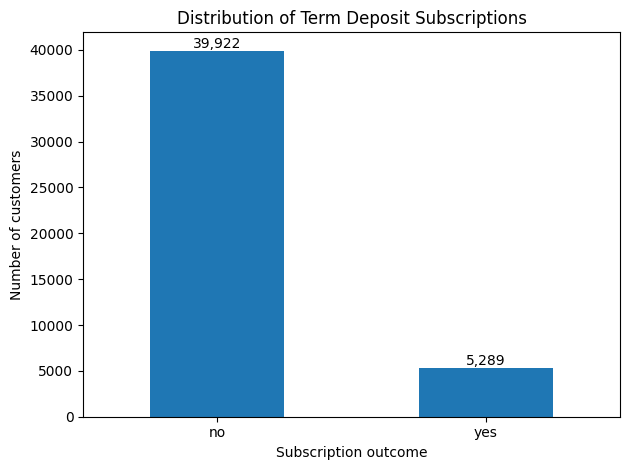

In [2]:
target_counts = df["y"].value_counts()

ax = target_counts.plot(kind="bar")

ax.set_title("Distribution of Term Deposit Subscriptions")
ax.set_xlabel("Subscription outcome")
ax.set_ylabel("Number of customers")
ax.tick_params(axis="x", rotation=0)

for index, value in enumerate(target_counts):
    ax.text(index, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Interpretation

The target distribution is clearly imbalanced.

Most customers did not subscribe to a term deposit, while only a relatively small proportion subscribed. This confirms that accuracy alone will not be sufficient when evaluating models later.

The minority class must be evaluated using metrics such as recall, precision, F1-score, ROC-AUC, and PR-AUC.

## Numerical feature distributions

Histograms are used to inspect the shape, spread, skewness, and possible extreme values of the numerical features.

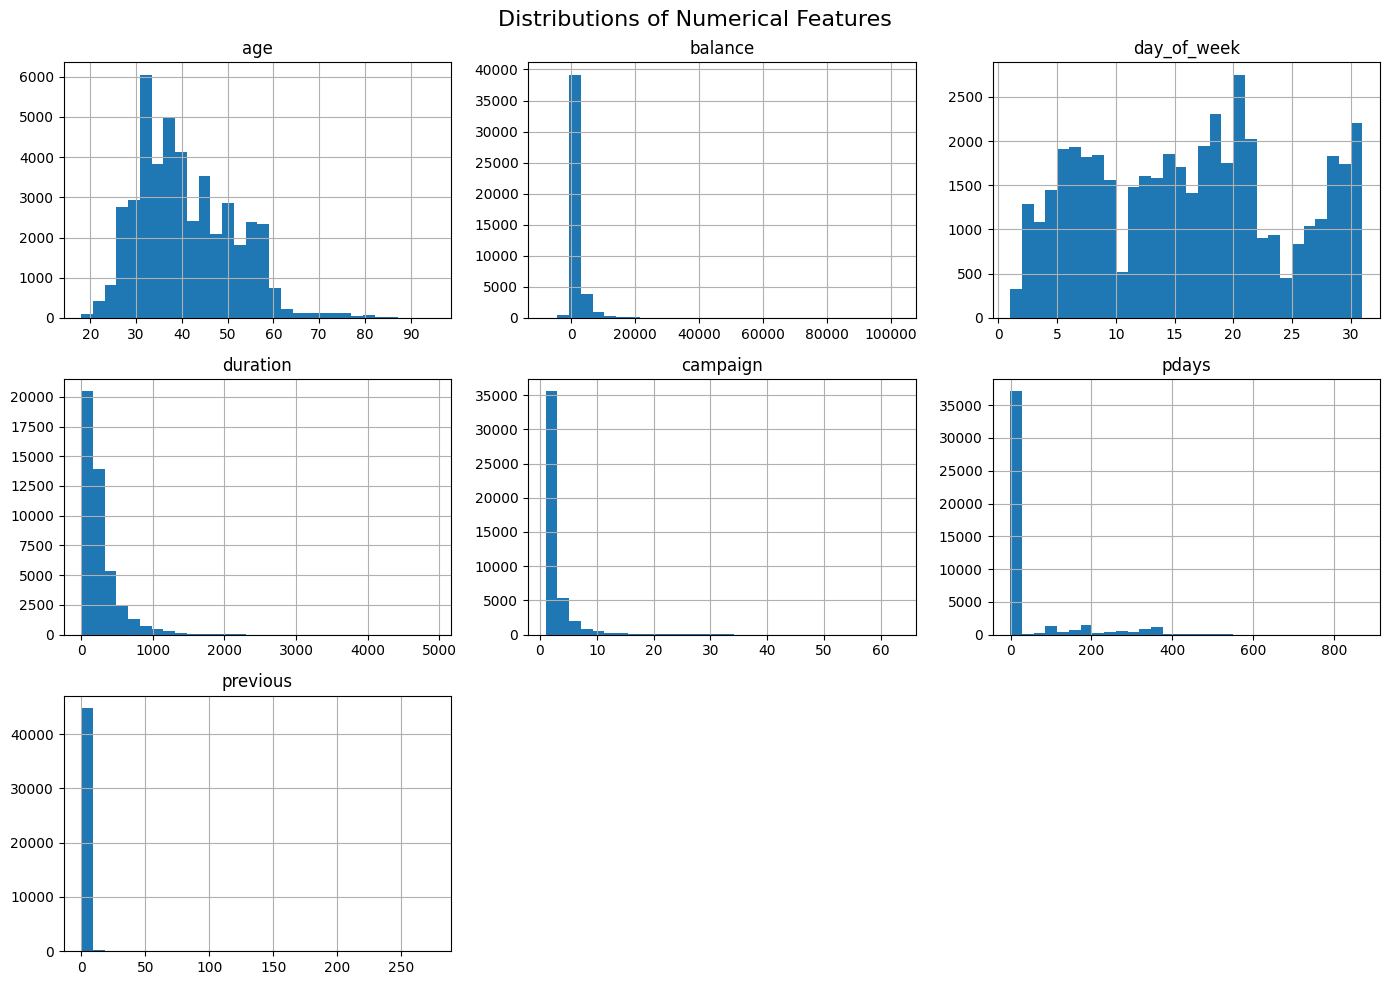

In [3]:
df[numerical_columns].hist(
    bins=30,
    figsize=(14, 10)
)

plt.suptitle("Distributions of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

### Interpretation

The numerical features have noticeably different distributions.

- `age` is moderately right-skewed, with most customers between approximately 30 and 50 years old.
- `balance` is strongly right-skewed. Most customers have relatively low balances, while a small number have extremely large balances.
- `duration` is also strongly right-skewed. Most marketing calls are relatively short, with a small number of unusually long calls.
- `campaign` shows that most customers were contacted only a few times during the current campaign.
- `pdays` is heavily concentrated around `-1`, which appears to represent customers who were not contacted during a previous campaign.
- `previous` is mostly zero, meaning most customers had no previous campaign contacts.
- `day_of_week` contains values from 1 to 31, indicating that it represents the day of the month despite its name.

These distributions suggest that scaling or transformations may benefit some models. However, extreme values will not be removed automatically because they may represent valid customer behaviour.

## Numerical outlier inspection

Boxplots are used to inspect potential extreme values in the numerical features.

Because the features use very different scales, each feature is plotted separately.

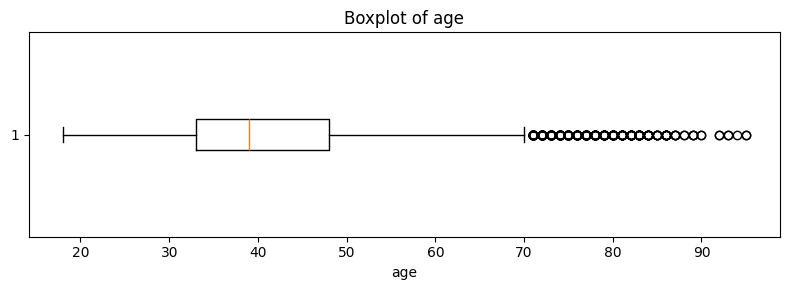

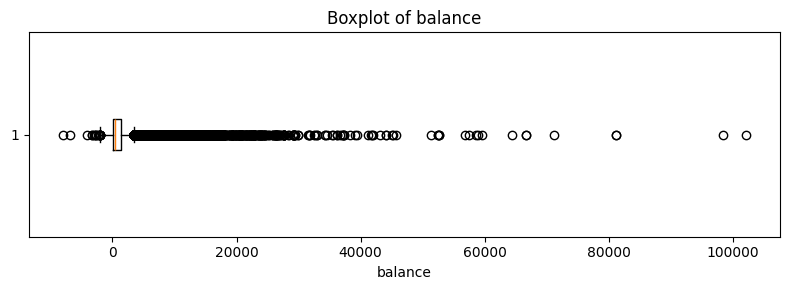

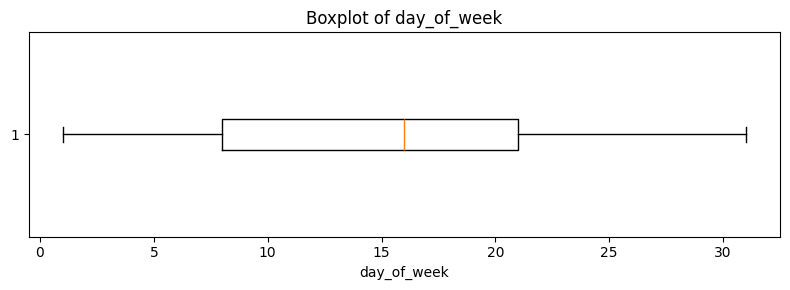

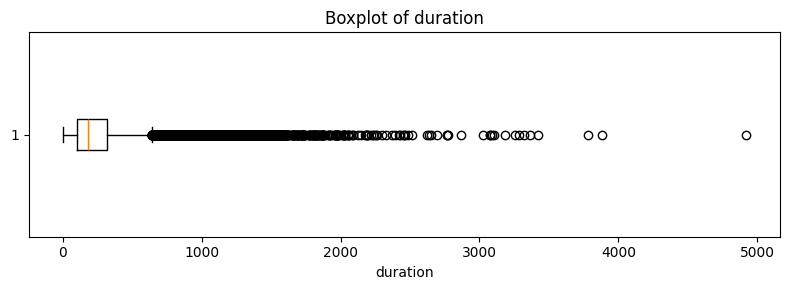

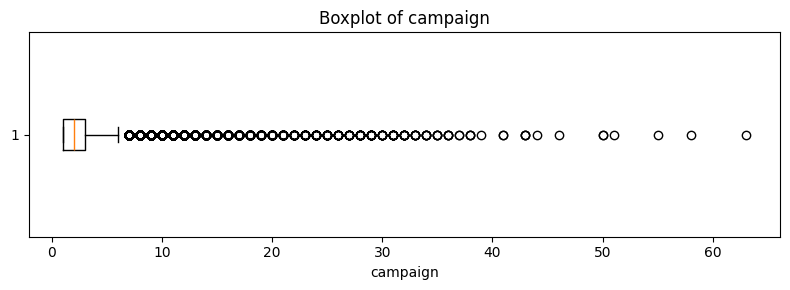

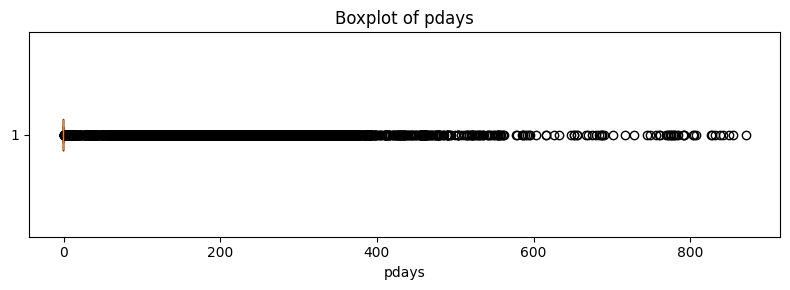

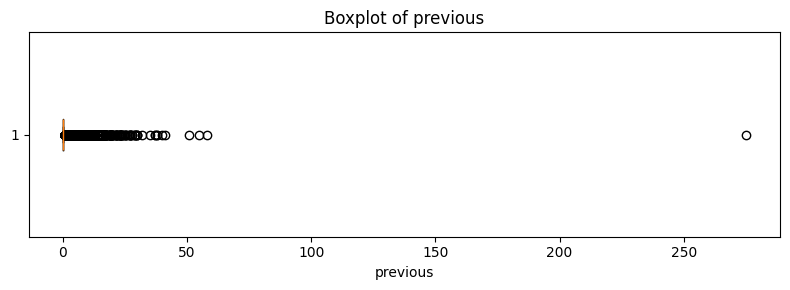

In [4]:
for column in numerical_columns:
    plt.figure(figsize=(8, 3))
    plt.boxplot(df[column].dropna(), vert=False)
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

### Interpretation

The boxplots confirm the presence of many statistical outliers in `balance`, `duration`, `campaign`, `pdays`, and `previous`.

These observations will not be removed automatically because they may represent valid customer behaviour rather than data-entry errors. The special value `pdays = -1` will also require separate handling because it represents no previous contact.

## Numerical features by subscription outcome

The numerical features are compared across the target classes to identify differences between customers who subscribed and those who did not.

In [5]:
for column in numerical_columns:
    grouped_summary = df.groupby("y")[column].agg(
        ["count", "mean", "median", "std"]
    )

    print(f"\nSummary of {column} by subscription outcome:")
    display(grouped_summary)


Summary of age by subscription outcome:


,count,mean,median,std
y,,,,
no,39922,40.838986,39.0,10.172662
yes,5289,41.670070,38.0,13.497781



Summary of balance by subscription outcome:


,count,mean,median,std
y,,,,
no,39922,1303.714969,417.0,2974.195473
yes,5289,1804.267915,733.0,3501.104777



Summary of day_of_week by subscription outcome:


...

,count,mean,median,std
y,,,,
no,39922,2.846350,2.0,3.212767
yes,5289,2.141047,2.0,1.921826



Summary of pdays by subscription outcome:


,count,mean,median,std
y,,,,
no,39922,36.421372,-1.0,96.757135
yes,5289,68.702968,-1.0,118.822266



Summary of previous by subscription outcome:


,count,mean,median,std
y,,,,
no,39922,0.502154,0.0,2.256771
yes,5289,1.170354,0.0,2.553272


### Interpretation

Several numerical features differ meaningfully between customers who subscribed and those who did not.

- `age` shows only a small difference between the two groups, so age alone is unlikely to be a strong predictor.
- Customers who subscribed had a higher average and median `balance`.
- `duration` shows the largest difference. Subscribed customers had much longer calls on average and at the median.
- Customers who subscribed were contacted slightly fewer times during the current `campaign`.
- `pdays` has the same median of `-1` for both groups, meaning most customers in both classes were not previously contacted. However, the higher mean for subscribers suggests that previously contacted customers may behave differently.
- `previous` is higher on average for customers who subscribed, suggesting that prior campaign contact may contain useful predictive information.
- `day_of_week` shows only a small difference between the target classes.

The strong relationship between `duration` and the target requires special caution. Call duration is only known after the call has taken place, so including it in a model intended to decide whom to contact beforehand would create a leakage-like deployment problem.

## Subscription rate by categorical feature

For each categorical feature, the proportion of customers who subscribed is calculated for every category.

This is more informative than comparing raw counts because some categories contain many more customers than others.

In [6]:
for column in categorical_columns:
    subscription_rate = (
        df.groupby(column, dropna=False)["y"]
        .apply(lambda values: (values == "yes").mean() * 100)
        .sort_values(ascending=False)
        .round(2)
    )

    print(f"\nSubscription rate by {column}:")
    display(subscription_rate.to_frame("subscription_rate_percentage"))


Subscription rate by job:


,subscription_rate_percentage
job,
student,28.68
retired,22.79
unemployed,15.50
management,13.76
admin.,12.20
self-employed,11.84
NaN,11.81
technician,11.06
services,8.88



Subscription rate by marital:


,subscription_rate_percentage
marital,
single,14.95
divorced,11.95
married,10.12



Subscription rate by education:


...

,subscription_rate_percentage
contact,
cellular,14.92
telephone,13.42
NaN,4.07



Subscription rate by month:


,subscription_rate_percentage
month,
mar,51.99
dec,46.73
sep,46.46
oct,43.77
apr,19.68
feb,16.65
aug,11.01
jun,10.22
nov,10.15



Subscription rate by poutcome:


,subscription_rate_percentage
poutcome,
success,64.73
other,16.68
failure,12.61
NaN,9.16


### Interpretation

Several categorical features show clear differences in subscription rates.

- Students and retired customers have the highest subscription rates by job, while blue-collar workers have the lowest.
- Single customers subscribe more often than married customers.
- Customers with tertiary education have a higher subscription rate than those with primary or secondary education.
- Customers without housing loans or personal loans subscribe more frequently.
- Cellular and telephone contacts perform considerably better than records with a missing contact type.
- March, December, September, and October show very high subscription rates, while May has the lowest rate.
- Customers whose previous campaign outcome was `success` have a much higher subscription rate than all other groups.

The strongest categorical relationship appears to be `poutcome`, where a previous successful campaign is associated with a subscription rate above 60%.

However, subscription percentages should be interpreted together with category counts. Some high-rate categories, particularly certain months or job groups, may contain relatively few observations.

## Key categorical relationships

Selected categorical features are visualized using subscription rates.

Only the most informative features are plotted to keep the analysis focused and readable.

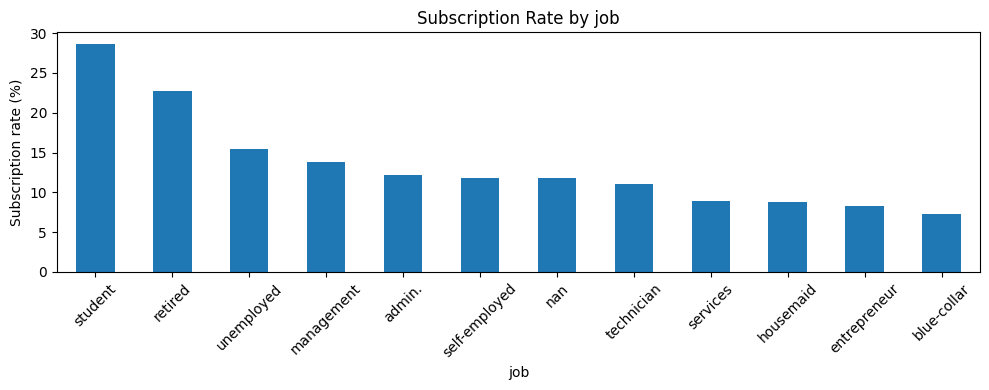

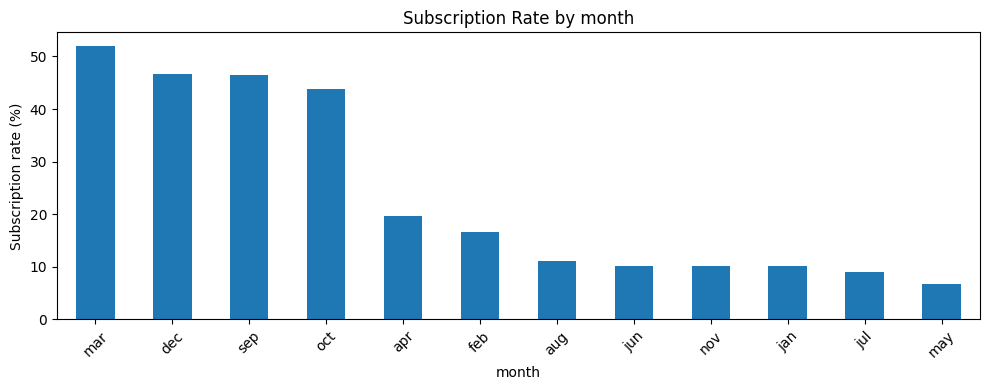

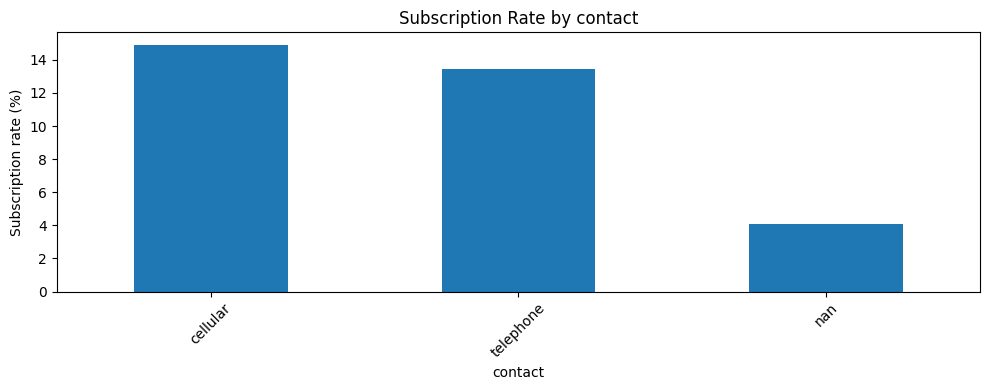

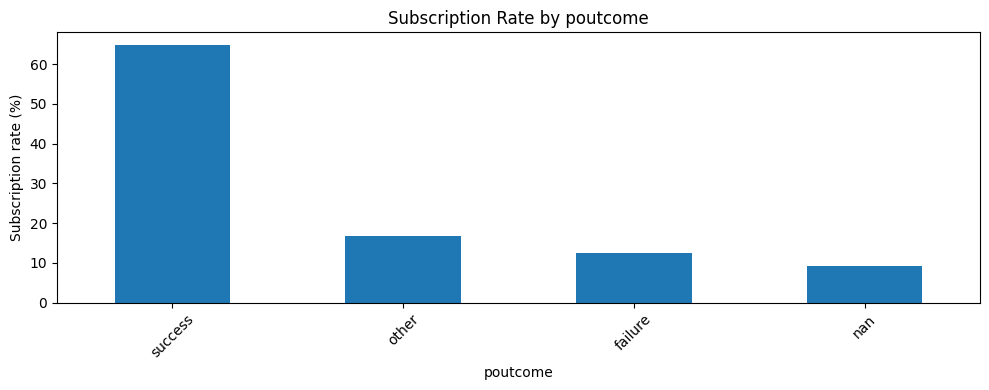

In [7]:
key_categorical_columns = ["job", "month", "contact", "poutcome"]

for column in key_categorical_columns:
    plot_data = (
        df.groupby(column, dropna=False)["y"]
        .apply(lambda values: (values == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(10, 4)
    )

    ax.set_title(f"Subscription Rate by {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Subscription rate (%)")
    ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

## Numerical feature correlations

A correlation matrix is used to inspect linear relationships between numerical features and identify possible redundancy.

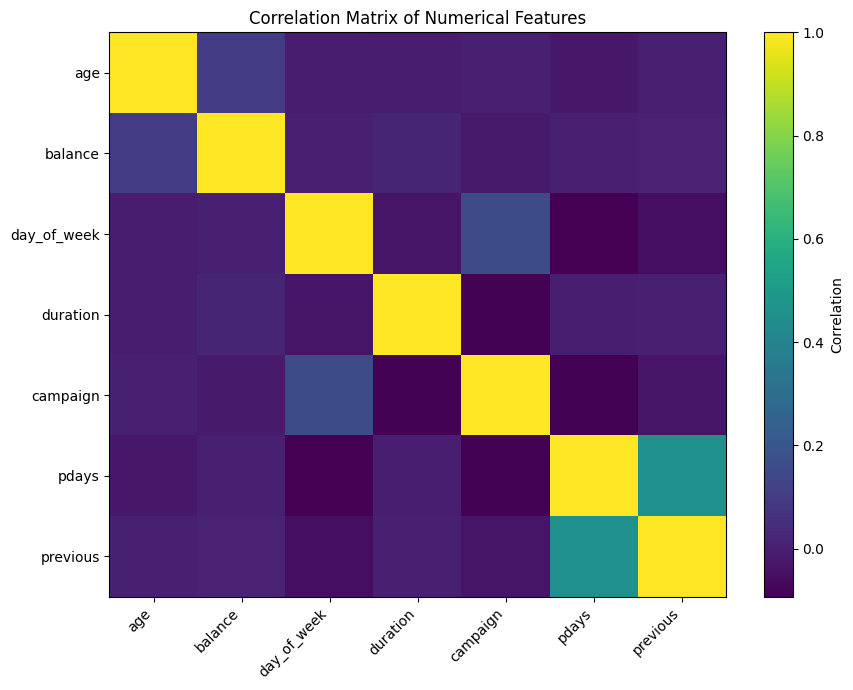

,age,balance,day_of_week,duration,campaign,pdays,previous
age,1.00,0.10,-0.01,-0.00,0.00,-0.02,0.00
balance,0.10,1.00,0.00,0.02,-0.01,0.00,0.02
day_of_week,-0.01,0.00,1.00,-0.03,0.16,-0.09,-0.05
duration,-0.00,0.02,-0.03,1.00,-0.08,-0.00,0.00
campaign,0.00,-0.01,0.16,-0.08,1.00,-0.09,-0.03
pdays,-0.02,0.00,-0.09,-0.00,-0.09,1.00,0.45
previous,0.00,0.02,-0.05,0.00,-0.03,0.45,1.00


In [8]:
correlation_matrix = df[numerical_columns].corr()

plt.figure(figsize=(9, 7))
plt.imshow(correlation_matrix, aspect="auto")
plt.colorbar(label="Correlation")

plt.xticks(
    range(len(numerical_columns)),
    numerical_columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numerical_columns)),
    numerical_columns
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

display(correlation_matrix.round(2))

### Interpretation

Most numerical features have weak linear relationships with one another.

The strongest correlation is between `pdays` and `previous`, at approximately 0.45. This is reasonable because both features describe previous marketing contact.

A weaker positive relationship exists between `day_of_week` and `campaign`, at approximately 0.16. The remaining correlations are close to zero.

Therefore, there is no evidence of severe multicollinearity among the numerical features. However, low linear correlation does not mean that the features are unimportant, because non-linear relationships may still exist.

## Duration and potential data leakage

The `duration` feature measures the length of the current marketing call.

It is strongly associated with subscription outcome, but it is only known after the call has already taken place. Therefore, it cannot be used in a model whose purpose is to decide which customers should be contacted before a campaign call begins.

Two modeling scenarios will later be considered:

1. A performance-oriented model that includes `duration`
2. A realistic pre-contact model that excludes `duration`

This comparison will show how much predictive performance depends on information that would not be available at the intended prediction time.

In [9]:
duration_summary = (
    df.groupby("y")["duration"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(duration_summary)

,count,mean,median,std,min,max
y,,,,,,
no,39922,221.18,164.0,207.38,0,4918
yes,5289,537.29,426.0,392.53,8,3881


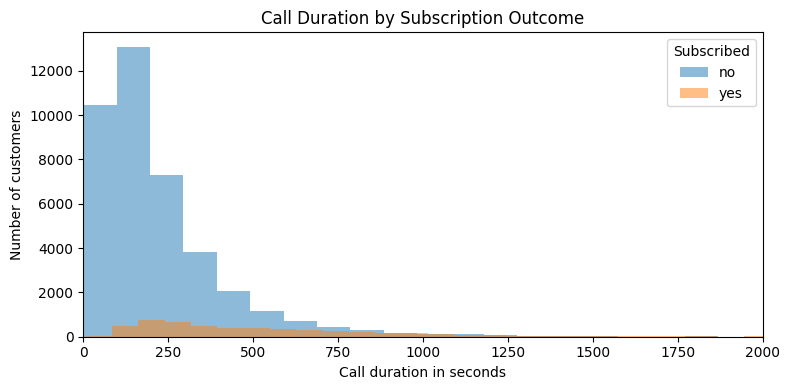

In [10]:
plt.figure(figsize=(8, 4))

for outcome in ["no", "yes"]:
    df.loc[df["y"] == outcome, "duration"].plot(
        kind="hist",
        bins=50,
        alpha=0.5,
        label=outcome
    )

plt.title("Call Duration by Subscription Outcome")
plt.xlabel("Call duration in seconds")
plt.ylabel("Number of customers")
plt.xlim(0, 2000)
plt.legend(title="Subscribed")
plt.tight_layout()
plt.show()

## EDA conclusion

The exploratory analysis identified several important characteristics of the dataset:

- The target variable is strongly imbalanced.
- Several numerical features are highly skewed and contain valid extreme values.
- Most numerical features have weak linear correlations with one another.
- Previous campaign outcome, contact type, campaign month, job, housing loan status, and personal loan status show meaningful differences in subscription rate.
- `poutcome` contains substantial missingness, but the missing category may itself contain useful information.
- `pdays = -1` represents a special state rather than a conventional numerical value.
- `duration` is strongly related to the target but would not be available before a marketing call.

